Dataset Shape: (2823, 25)

First 5 rows:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1    

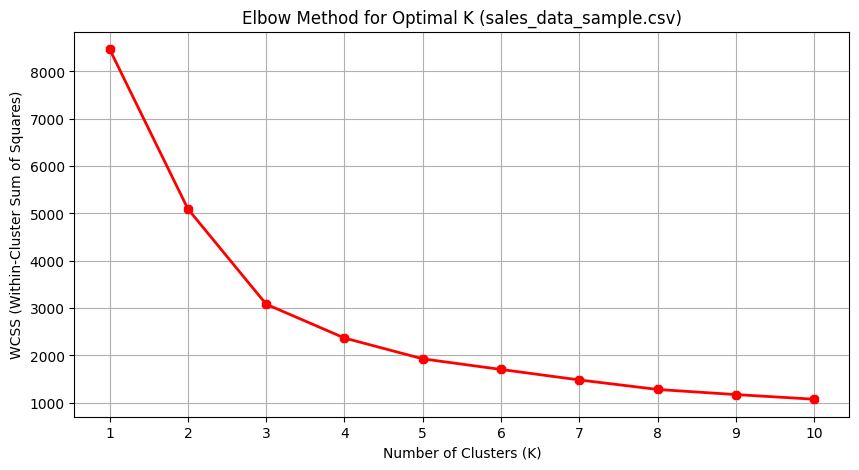

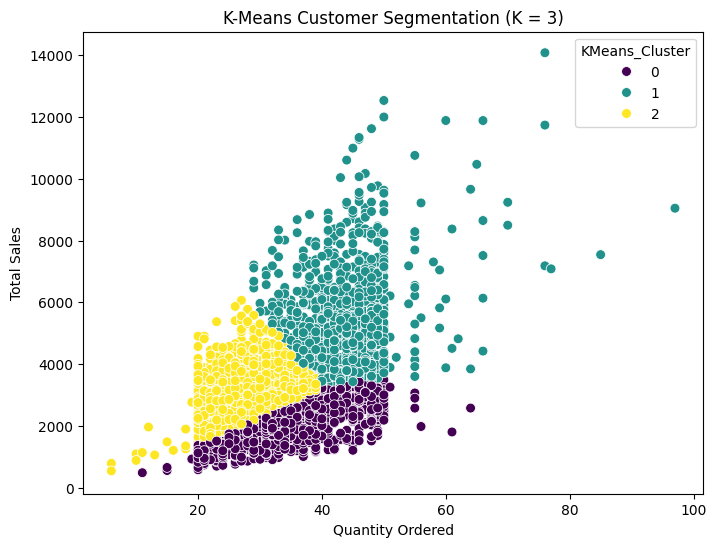

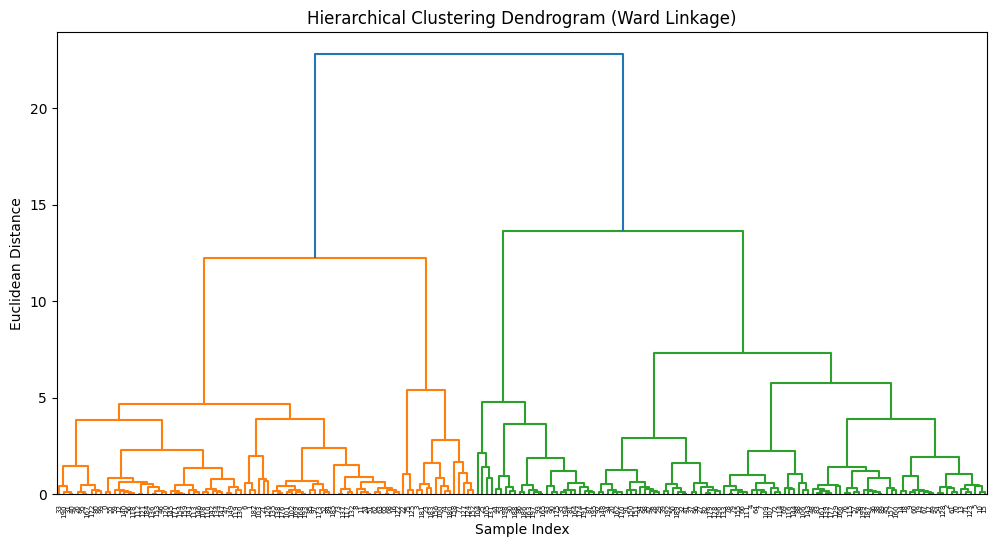

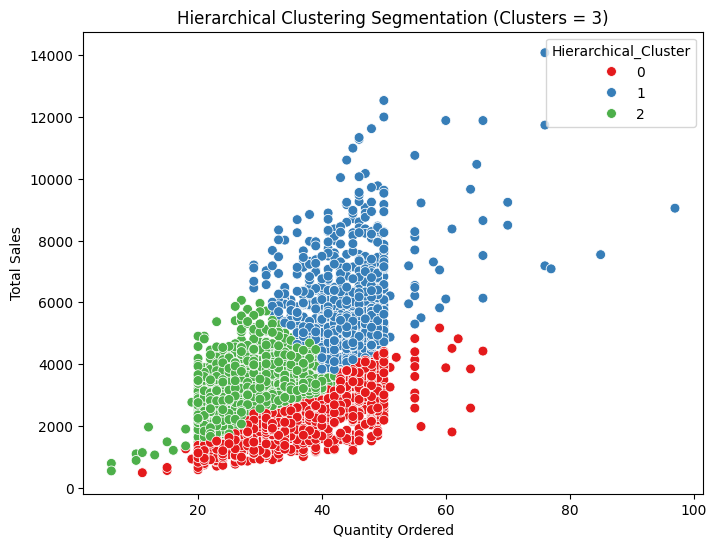


--- K-Means Cluster Profiles (Mean Values) ---
                QUANTITYORDERED  PRICEEACH        SALES
KMeans_Cluster                                         
0                     35.125993  57.130216  2009.829955
1                     43.847850  96.637795  5584.007299
2                     27.392271  94.865575  3089.153662

--- Hierarchical Cluster Profiles (Mean Values) ---
                      QUANTITYORDERED  PRICEEACH        SALES
Hierarchical_Cluster                                         
0                           36.577909  60.350631  2238.072268
1                           44.083212  99.451168  6081.749635
2                           28.274021  95.060925  3200.378176


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch

# -----------------------------------------------------------
# 1. Load the Dataset
# -----------------------------------------------------------
# Note: sales_data_sample.csv often requires 'unicode_escape' or 'latin1' encoding
try:
    df = pd.read_csv("sales_data_sample.csv", encoding="unicode_escape")
except UnicodeDecodeError:
    df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# -----------------------------------------------------------
# 2. Data Preprocessing & Feature Selection
# -----------------------------------------------------------
# Display column names to verify available numeric sales metrics
print("\nColumns available:", df.columns.tolist())

# Select relevant numeric features for customer/order segmentation:
# QUANTITYORDERED: Volume of items bought per order
# PRICEEACH: Price per individual unit
# SALES: Total sales amount per transaction line
features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]

# Subset and drop any missing values in the chosen dimensions
data_cluster = df[features].dropna().copy()

# Feature Scaling (Crucial for distance-based clustering algorithms)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_cluster)

# -----------------------------------------------------------
# 3. K-Means: Determine Optimal Clusters using the Elbow Method
# -----------------------------------------------------------
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(k_range, wcss, marker="8", color="red", linewidth=2)
plt.title("Elbow Method for Optimal K (sales_data_sample.csv)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.xticks(np.arange(1, 11, 1))
plt.grid(True)
plt.show()

# -----------------------------------------------------------
# 4. Fit K-Means with Optimal K (e.g., K = 3 or 4 from elbow)
# -----------------------------------------------------------
optimal_k = 3
kmeans_model = KMeans(n_clusters=optimal_k, init="k-means++", random_state=42)
data_cluster["KMeans_Cluster"] = kmeans_model.fit_predict(X_scaled)

# Scatter plot of K-Means Clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="QUANTITYORDERED",
    y="SALES",
    hue="KMeans_Cluster",
    palette="viridis",
    data=data_cluster,
    s=50
)
plt.title(f"K-Means Customer Segmentation (K = {optimal_k})")
plt.xlabel("Quantity Ordered")
plt.ylabel("Total Sales")
plt.show()

# -----------------------------------------------------------
# 5. Hierarchical Clustering (Agglomerative)
# -----------------------------------------------------------
# Visualizing Dendrogram (sampled on the first 200 records for clear tree visualization)
plt.figure(figsize=(12, 6))
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")
dendrogram = sch.dendrogram(sch.linkage(X_scaled[:200], method="ward"))
plt.show()

# Fit Agglomerative Clustering
agg_clustering = AgglomerativeClustering(n_clusters=optimal_k, metric="euclidean", linkage="ward")
data_cluster["Hierarchical_Cluster"] = agg_clustering.fit_predict(X_scaled)

# Scatter plot of Hierarchical Clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="QUANTITYORDERED",
    y="SALES",
    hue="Hierarchical_Cluster",
    palette="Set1",
    data=data_cluster,
    s=50
)
plt.title(f"Hierarchical Clustering Segmentation (Clusters = {optimal_k})")
plt.xlabel("Quantity Ordered")
plt.ylabel("Total Sales")
plt.show()

# -----------------------------------------------------------
# 6. Cluster Profiling / Mean Statistics
# -----------------------------------------------------------
print("\n--- K-Means Cluster Profiles (Mean Values) ---")
print(data_cluster.groupby("KMeans_Cluster")[features].mean())

print("\n--- Hierarchical Cluster Profiles (Mean Values) ---")
print(data_cluster.groupby("Hierarchical_Cluster")[features].mean())